# HW2：King County 房價多元線性回歸（主程式）

本 notebook 是 HW2 的主程式，也是報告、README 與 dashboard 全部數字的唯一來源。它依 CRISP-DM 六個階段組織，呼叫單元內的 `hw2` 套件，並把結果匯出到 `results/` 與 `assets/model_data.js`。

- 在 repo 內的檔名是 `hw2.ipynb`；繳交時由打包步驟從同一份檔案複製成 `<學號>_hw2.ipynb`。
- 執行方式見單元 `README.md`（從 `home_work_02/` 以非互動方式執行全部 cell）。
- 固定 seed、鎖版本的 `requirements.txt`：在乾淨環境重跑可得到相同的切分與數字。

In [1]:
import sys
from pathlib import Path

UNIT_DIR = Path.cwd()
if not (UNIT_DIR / "hw2").is_dir():
    raise RuntimeError("run this notebook from home_work_02/")
sys.path.insert(0, str(UNIT_DIR))

import numpy as np
import pandas as pd

from hw2 import (comparison, contract, data, export, models, paths, preprocess, selection,
                 testgate)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


def rel(path):
    """A path relative to the unit directory when it is inside it."""
    try:
        return path.relative_to(UNIT_DIR).as_posix()
    except ValueError:
        return path.as_posix()

export.package_versions()

{'python': '3.11.2',
 'numpy': '2.4.6',
 'pandas': '3.0.6',
 'scipy': '1.17.1',
 'scikit-learn': '1.9.1',
 'matplotlib': '3.11.2'}

## 1. Business Understanding

**目標**：以 King County（美國華盛頓州，含 Seattle）2014-05 至 2015-05 的房屋成交紀錄，建立多元線性回歸模型預測成交價，並為每一筆預測提供有統計定義的 95% 預測區間。

**研究問題**

1. 在四種具有 k = 1…18 路徑的特徵選擇方法（Forward SFS、Backward SFS、RFE、Lasso 路徑排序取 top-k）與單一的 All-in baseline 之中，哪一個在訓練集交叉驗證下的預測誤差最小？
2. 被選出的模型在保留的 Test set 上表現如何？逐筆 95% 預測區間的經驗涵蓋率是多少？
3. 哪些房屋特徵與價格的關聯最強？模型的假設與限制是什麼？

**成功標準**

- 模型選擇只用訓練集：以房屋 `id` 分組的 5-fold 交叉驗證、USD 尺度的 CV RMSE。
- Test set 在全部選擇固定之後只評估一次，報告 MAE、MSE、RMSE、R²（USD）與預測區間的涵蓋率；不以 Test 結果更換模型。
- 結果可重現：固定 seed、鎖版本的套件、資料檔以 sha256 核對。

**資料來源**：Kaggle「House Sales in King County, USA」（`harlfoxem/housesalesprediction`），授權 CC0: Public Domain。本專案使用的檔案是 acceptor 於 2026-10-18 提供的 GitHub 鏡像，其 sha256 與 Brief 釘住的值相同（下方程式核對）。

**特徵數的規則**：作業頁正文寫「至 Kaggle 選擇一個具有 10 至 20 個特徵 (features) 的公開資料集。」，補充段寫「choose features > 13, < 40」。本專案採兩者的交集 14–20，在類別編碼前計數、不含識別欄 `id` 與目標 `price`：

- **Source features 19 個**（CSV 21 欄扣除 `id`、`price`），落在 14–20 之內。
- **建模 feature groups 18 個**：`sqft_basement` 不進模型，因為每一列都有 `sqft_living = sqft_above + sqft_basement`，三欄完全共線。特徵選擇以 feature group 為單位（例如 `zipcode` 與它的全部 one-hot 欄同進同出），k 計的是 group 數。

In [2]:
print(data.DATASET["name"], "|", data.DATASET["kaggle_slug"], "|", data.DATASET["license"])
print("source features:", len(preprocess.SOURCE_FEATURES), list(preprocess.SOURCE_FEATURES))
print("feature groups :", len(preprocess.FEATURE_GROUPS), list(preprocess.FEATURE_GROUPS))
print("excluded       :", preprocess.EXCLUDED_SOURCE_FEATURES)

House Sales in King County, USA | harlfoxem/housesalesprediction | CC0: Public Domain (CC0-1.0)
source features: 19 ['date', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
feature groups : 18 ['date', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
excluded       : {'sqft_basement': 'sqft_living = sqft_above + sqft_basement on every row, so the three columns are perfectly collinear; sqft_basement is dropped and the other two stay'}


## 2. Data Understanding

### 2.1 全資料層級：只做結構驗證

先以 sha256 核對資料檔，再解析 CSV，並檢查 schema（21 欄與欄位順序）、列數 21,613、唯一 `id` 數 21,436、沒有缺值，以及每一列的 `sqft_living = sqft_above + sqft_basement`。任一項不符就以錯誤停止。

全資料層級只做這些結構檢查。接著立即以房屋 `id` 分組切出 Test set：資料階段只回傳 training 列與 Test 列的識別（CSV 列序號與 `id`）及 n_test，不回傳 Test 列的特徵或價格。價格與特徵的分布統計、極端值都只用 training 列計算。

In [3]:
prepared = data.load_and_split()
print("sha256        :", prepared.sha256)
print("structure     :", prepared.facts)
print("n_train/n_test:", prepared.n_train, prepared.n_test,
      f"(test share {prepared.n_test / (prepared.n_train + prepared.n_test):.4f})")
print("timing (s)    :", prepared.timings_s)

sha256        : d0875baa0251b21d4bdc9d2ae940a4fe0bb6009824f23dd0e2a5b2bf04557b7e
structure     : {'n_rows': 21613, 'n_columns': 21, 'n_unique_ids': 21436, 'n_repeat_sales': 177, 'sqft_identity_holds': True}
n_train/n_test: 17290 4323 (test share 0.2000)
timing (s)    : {'data_load_validate': 0.0345, 'split_and_folds': 0.0167}


### 2.2 Training set 的分布（只用 training 列）

以下統計全部來自 training 列。價格分布右偏，所以模型以 ln(price) 為目標，預測與指標再轉回 USD 報告。

In [4]:
train = prepared.training
price = pd.DataFrame({"price (USD)": train["price"], "ln(price)": np.log(train["price"])})
price.describe().T

,count,mean,std,min,25%,50%,75%,max
price (USD),17290.0,537754.460150,360059.981568,75000.000000,320000.000000,450000.000000,641000.000000,7.700000e+06
ln(price),17290.0,13.045136,0.525038,11.225243,12.676076,13.017003,13.370785,1.585673e+01


In [5]:
numeric = [f for f in preprocess.SOURCE_FEATURES if f not in ("date", "zipcode")]
train[numeric].describe().T

,count,mean,std,min,25%,50%,75%,max
bedrooms,17290.0,3.371718,0.935417,0.0000,3.0000,3.0000,4.0000,3.300000e+01
bathrooms,17290.0,2.109905,0.769467,0.0000,1.5000,2.2500,2.5000,8.000000e+00
sqft_living,17290.0,2075.460844,914.613101,290.0000,1420.0000,1910.0000,2550.0000,1.354000e+04
sqft_lot,17290.0,15065.460266,39361.979524,520.0000,5056.5000,7620.0000,10712.5000,1.164794e+06
floors,17290.0,1.494043,0.540022,1.0000,1.0000,1.5000,2.0000,3.500000e+00
waterfront,17290.0,0.007403,0.085725,0.0000,0.0000,0.0000,0.0000,1.000000e+00
view,17290.0,0.232042,0.761708,0.0000,0.0000,0.0000,0.0000,4.000000e+00
condition,17290.0,3.411625,0.649326,1.0000,3.0000,3.0000,4.0000,5.000000e+00
grade,17290.0,7.650839,1.171092,1.0000,7.0000,7.0000,8.0000,1.300000e+01
sqft_above,17290.0,1785.273569,824.804018,290.0000,1190.0000,1560.0000,2210.0000,9.410000e+03


In [6]:
days = preprocess.sale_days(train["date"])
print("sale dates     :", preprocess.days_to_iso(days.min()), "to", preprocess.days_to_iso(days.max()))
print("zipcodes       :", train["zipcode"].nunique(), "categories in the training rows")
print("renovated rows :", int((train["yr_renovated"] > 0).sum()), "of", len(train))
n_houses = train["id"].nunique()
print("training houses:", n_houses, "| repeat sales in training:", len(train) - n_houses)

sale dates     : 2014-05-02 to 2015-05-27
zipcodes       : 70 categories in the training rows
renovated rows : 716 of 17290
training houses: 17149 | repeat sales in training: 141


### 2.3 極端值（只用 training 列；不刪除）

異常值不刪除也不截尾；這裡列出 training 列中的極端值，之後在模型診斷中討論它們的影響。

In [7]:
cols = ["row", "id", "date", "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "grade", "zipcode"]
print("highest prices"); display(train.nlargest(5, "price")[cols])
print("lowest prices"); display(train.nsmallest(5, "price")[cols])
print("most bedrooms"); display(train.nlargest(3, "bedrooms")[cols])
print("largest living area"); display(train.nlargest(3, "sqft_living")[cols])

highest prices


,row,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,grade,zipcode
5784,7252,6762700020,20141013T000000,7700000.0,6,8.0,12050,27600,13,98102
3145,3914,9808700762,20140611T000000,7062500.0,5,4.5,10040,37325,11,98004
1053,1315,7558700030,20150413T000000,5300000.0,6,6.0,7390,24829,12,98040
2120,2626,7738500731,20140815T000000,4500000.0,5,5.5,6640,40014,12,98155
6869,8638,3835500195,20140618T000000,4489000.0,4,3.0,6430,27517,12,98004


lowest prices


,row,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,grade,zipcode
913,1149,3421079032,20150217T000000,75000.0,1,0.0,670,43377,3,98022
12263,15293,0040000362,20140506T000000,78000.0,2,1.0,780,16344,5,98168
12981,16198,3028200080,20150324T000000,81000.0,2,1.0,730,9975,5,98168
6585,8274,3883800011,20141105T000000,82000.0,3,1.0,860,10426,6,98146
1735,2141,1623049041,20140508T000000,82500.0,2,1.0,520,22334,5,98168


most bedrooms


,row,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,grade,zipcode
12730,15870,2402100895,20140625T000000,640000.0,33,1.75,1620,6000,7,98103
6966,8757,1773100755,20140821T000000,520000.0,11,3.00,3000,4960,7,98106
10672,13314,0627300145,20140814T000000,1148000.0,10,5.25,4590,10920,9,98004


largest living area


,row,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,grade,zipcode
10238,12777,1225069038,20140505T000000,2280000.0,7,8.0,13540,307752,12,98053
5784,7252,6762700020,20141013T000000,7700000.0,6,8.0,12050,27600,13,98102
3145,3914,9808700762,20140611T000000,7062500.0,5,4.5,10040,37325,11,98004


## 3. Data Preparation

### 3.1 固定的逐列轉換（不需 fit，對所有候選相同）

- `date` → `sale_days`：距固定基準日 2014-01-01 的天數。
- `yr_renovated` → `is_renovated`（有整修為 1）與 `yr_renovated_effective`（有整修時為整修年，否則為 `yr_built`）；兩欄同屬 `yr_renovated` 這個 group。
- `zipcode` 視為類別（nominal）。
- `sqft_basement` 不進模型；其餘欄位照原值。

In [8]:
example = train.head(3)[["row", "date", "yr_built", "yr_renovated", "zipcode"]].copy()
example["sale_days"] = preprocess.sale_days(example["date"])
example["is_renovated"], example["yr_renovated_effective"] = preprocess.renovation_columns(
    example["yr_renovated"], example["yr_built"])
example

,row,date,yr_built,yr_renovated,zipcode,sale_days,is_renovated,yr_renovated_effective
0,0,20141013T000000,1955,0,98178,285,0,1955
1,1,20141209T000000,1951,1991,98125,342,1,1991
2,2,20150225T000000,1933,0,98028,420,0,1933


### 3.2 需要 fit 的前處理（只以當次訓練列 fit）

- `zipcode` one-hot：類別取自當次訓練列，排序後的第一個類別是基準類別、不建欄；預測時遇到未見類別，編為基準類別。
- 數值欄的標準化只用於 Ridge／Lasso；OLS 子集模型以原始尺度擬合，係數可以直接解讀。

在交叉驗證中，每個 fold 都只用該 fold 的訓練列 fit；下面是以整個 training set fit 的結果，供 dashboard 與匯出使用。

In [9]:
full_fit = preprocess.fit_preprocessor(train)
print("encoded columns:", len(full_fit.columns))
print("zipcode categories:", len(full_fit.zipcode_categories), "| baseline:", full_fit.zipcode_baseline)
print(full_fit.columns[:20], "...")

encoded columns: 87
zipcode categories: 70 | baseline: 98001
('sale_days', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'yr_built', 'is_renovated', 'yr_renovated_effective', 'zipcode_98002', 'zipcode_98003', 'zipcode_98004', 'zipcode_98005', 'zipcode_98006', 'zipcode_98007') ...


### 3.3 分組交叉驗證的 fold

在 training set 內以房屋 `id` 分組產生 5 個 fold，只產生一次，所有方法、所有 k 與 Ridge／Lasso 都共用同一組 fold。

In [10]:
folds = train.groupby("fold").agg(rows=("row", "size"), houses=("id", "nunique"))
folds["price median (USD)"] = train.groupby("fold")["price"].median()
houses = [set(train.loc[train["fold"] == f, "id"]) for f in range(prepared.n_folds)]
assert all(houses[a].isdisjoint(houses[b]) for a in range(5) for b in range(a + 1, 5))
folds

,rows,houses,price median (USD)
fold,,,
0,3454,3430,453000.0
1,3462,3430,450000.0
2,3461,3430,449400.0
3,3456,3430,451200.5
4,3457,3429,449999.0


### 3.4 切分紀錄

`results/split/split_assignment.csv` 記錄每一筆交易屬於 training 或 Test 與其 fold 編號（只有識別，沒有特徵或價格）。`model_data` 在第 5 章最後匯出。Test 列的特徵與價格只能經由 Test 評估守門（G-3）載入，而守門只在全部模型選擇與 alpha 固定之後開啟。

In [11]:
split_path = export.write_split_assignment(prepared)
print(rel(split_path), split_path.stat().st_size, "bytes")

results/split/split_assignment.csv 520585 bytes


## 4. Modeling

### 4.1 All-in baseline

All-in baseline 是以全部 18 個 feature group 擬合的**單一** OLS 模型（log(price) 尺度、原始尺度的特徵），沒有 k 路徑；它等於 Forward、Backward、RFE 路徑在 k = 18 的端點，本身就是自己的 CV winner。

- **交叉驗證**：在 training set 內的 5 個分組 fold 上，每個 fold 只用該 fold 的訓練列 fit 前處理（zipcode 類別）與 OLS，再以 exp(log 預測) 在驗證列上計算 USD 尺度的 MAE、MSE、RMSE、R²；CV 指標是 5 折的平均，另記各折值與標準差。
- **全訓練集擬合（`fit`）**：在整個 training set 上擬合同一個模型，記錄 log 尺度的 R² 與 Adjusted R²、design matrix 的欄數與實際 rank、df_resid、s²、t 臨界值、係數與 (XᵀX)⁻¹，供即時預測器與預測區間使用。
- **秩不足**：某個 zipcode 不在某個 fold 的訓練列中時，該 fold 的設計矩陣沒有那一欄（合法的 encoding 結果），驗證列中的這個 zipcode 編為基準類別並計數。All-in 在任一 fold 或整個 training set 上秩不足屬於實驗層級的失敗：程式以錯誤停止並列出原因，不刪欄、不合併類別。
- Adjusted R² 以 n_train 與實際 model rank（含截距）套古典公式 1 − (1 − R²)(n − 1)/(n − rank)，只在 log 尺度、只對 OLS 子集模型計算。

In [12]:
allin = models.fit_allin(train)
allin_entry = allin.to_entry()
print("timing (s):", allin.timing_s)
folds_table = pd.DataFrame(allin_entry["cv"]["folds"])[
    ["fold", "n_train", "n_valid", "n_columns", "rank", "n_valid_unseen_zipcode", "rmse", "mae", "r2"]]
folds_table

timing (s): {'cv': 0.4691, 'canonical_fit': 0.0744}


,fold,n_train,n_valid,n_columns,rank,n_valid_unseen_zipcode,rmse,mae,r2
0,0,13836,3454,88,88,0,170458.683401,77283.656551,0.813372
1,1,13828,3462,88,88,0,150110.947109,75924.856625,0.818369
2,2,13829,3461,88,88,0,124353.836024,75246.612533,0.875840
3,3,13834,3456,88,88,0,213966.579303,75463.096477,0.653456
4,4,13833,3457,88,88,0,131881.516776,74369.965548,0.844203


In [13]:
cv = allin_entry["cv"]
pd.DataFrame({"mean": cv["mean"], "std (ddof=1)": cv["std"]}).T

,mae,mse,rmse,r2
mean,75657.637547,2.604555e+10,158154.312523,0.801048
std (ddof=1),1070.073690,1.222455e+10,35929.912333,0.086156


In [14]:
fit = allin_entry["fit"]
{k: fit[k] for k in ("n_train", "n_columns", "rank", "df_resid", "r2_log", "adj_r2_log", "s2", "t_crit")}

{'n_train': 17290,
 'n_columns': 88,
 'rank': 88,
 'df_resid': 17202,
 'r2_log': 0.8790764857352393,
 'adj_r2_log': 0.8784649088406321,
 's2': 0.03350298308697721,
 't_crit': 1.9601019007892466}

### 4.2 特徵選擇路徑：四種方法，k = 1…18

四種有 k 路徑的方法都以 **feature group** 為單位（例如 `zipcode` 與它的全部 one-hot 欄同進同出），每一步只加入或移除一個 group，所以 k 與 k+1 的子集恰差一個 group：

- **Forward SFS**：從空集合開始，每一步加入「加入後 OLS（ln(price)）在給定列上的殘差平方和 RSS 最小」的 group。
- **Backward SFS**：從全部 18 個 group 開始，每一步移除「移除後 RSS 最小」的 group。
- **RFE**：從全部 18 個 group 開始，每一步以目前的 group 擬合 OLS，移除重要度最小的 group。**Group 重要度的彙總規則**：該 group 對擬合 ln(price) 的貢獻 X_g·β_g 在給定列上的標準差。它與欄位尺度無關；單一欄的 group 就是 |β|·sd(x)（標準化係數）；`zipcode` 的 69 個 one-hot 欄與整修的兩欄各視為一個整體。
- **Lasso 路徑排序**：以 Ridge／Lasso 的標準化（只在給定列上 fit；數值欄標準化、zipcode one-hot 維持 0／1）計算 LARS 的精確 Lasso 路徑；group 內任一欄係數首次非零時該 group 進入，k 的子集是最先進入的 k 個 group；從未進入的 group 排在最後。

**平手**依 canonical order（CSV 欄位順序）：Forward 與 Lasso 先加入較前面的 group，Backward 與 RFE 先移除較後面的 group。**秩不足**不會停止或跳過任何一步：準則用最小範數的最小平方解，在給定列上為常數或完全共線的 group 只是沒有貢獻；子集能否擬合由下一步的候選評估判定（invalid 候選），All-in 秩不足則是實驗層級的失敗。

**選擇邊界（fold-internal selection）**：每個 fold 的路徑只在該 fold 的訓練列（其他四個 fold 的列）上計算，再以該 fold 的子集在同一批訓練列上擬合 OLS、在驗證列上算 USD 指標；驗證列不參與任何子集的選擇。另在**整個 training set** 上計算一次 **canonical subset**：它是 dashboard 顯示的 groups、即時預測器與（若是 CV winner）Test 評估所用的模型。因此同一方法同一 k 在不同 fold 的子集可能不同，CV 指標估計的是「這個方法在 k 下的程序」的表現，不是 canonical subset 本身的表現。

上面的 RSS 與重要度只用來排序 group；每個方法的 k 由下一節的分組 5-fold CV RMSE（USD）決定。執行時間逐一量測並記錄（Q34）；不因成本縮小 k 的範圍或方法集合。Ridge／Lasso 對照模型與講義的 p-value backward 對照見 4.3、4.4。

In [15]:
path_candidates, path_runs, path_timing = selection.run_path_methods(train)
timing_table = pd.DataFrame({
    models.METHOD_LABELS[m]: {"選擇：5 個 fold（秒）": sum(t["selection_folds"]),
                              "選擇：整個 training set（秒）": t["selection_training"],
                              "CV 與 canonical fit，k=1…18（秒）": t["evaluation"],
                              "合計（秒）": t["total"]}
    for m, t in path_timing.items()}).T
timing_table.round(2)

,選擇：5 個 fold（秒）,選擇：整個 training set（秒）,CV 與 canonical fit，k=1…18（秒）,合計（秒）
Forward SFS,0.54,0.11,7.72,8.37
Backward SFS,0.55,0.12,7.87,8.53
RFE,0.24,0.05,7.01,7.30
Lasso 路徑排序,0.71,0.16,3.15,4.03


In [16]:
def added_at(subsets, k):
    previous = set(subsets[k - 2]) if k > 1 else set()
    return (set(subsets[k - 1]) - previous).pop()

canonical_steps = pd.DataFrame(
    {models.METHOD_LABELS[m]: [added_at(path_runs[m].canonical.subsets, k) for k in range(1, 19)]
     for m in models.PATH_METHODS}, index=pd.Index(range(1, 19), name="k"))
print("canonical path (whole training set): the group that enters the subset at each k")
canonical_steps

canonical path (whole training set): the group that enters the subset at each k


,Forward SFS,Backward SFS,RFE,Lasso 路徑排序
k,,,,
1,zipcode,zipcode,sqft_living,grade
2,sqft_living,sqft_living,zipcode,sqft_living
3,grade,grade,grade,lat
4,view,view,lat,sqft_living15
5,waterfront,waterfront,view,view
6,condition,condition,sqft_living15,yr_built
7,sqft_living15,sqft_living15,long,condition
8,sqft_lot,sqft_lot,sqft_above,waterfront
9,date,date,condition,bathrooms


In [17]:
cv_rmse = pd.DataFrame({models.METHOD_LABELS[m]: [c.cv_rmse for c in cands]
                        for m, cands in path_candidates.items()},
                       index=pd.Index(range(1, 19), name="k"))
folds_agree = pd.DataFrame({models.METHOD_LABELS[m]: [c.to_entry()["folds_agree"] for c in cands]
                            for m, cands in path_candidates.items()},
                           index=pd.Index(range(1, 19), name="k"))
invalid = [(c.key, c.status) for cands in path_candidates.values() for c in cands if not c.valid]
print("All-in baseline CV RMSE (USD):", round(allin.cv_rmse, 1))
print("invalid candidates:", invalid if invalid else "none")
display(cv_rmse.round(0))
print("number of folds (of 5) whose subset equals the canonical subset")
folds_agree

All-in baseline CV RMSE (USD): 158154.3
invalid candidates: none


,Forward SFS,Backward SFS,RFE,Lasso 路徑排序
k,,,,
1,282383.0,282383.0,370575.0,256471.0
2,268334.0,268334.0,268334.0,244278.0
3,187346.0,187346.0,187346.0,235730.0
4,184222.0,184766.0,191022.0,226903.0
5,185465.0,184998.0,186804.0,224487.0
6,179159.0,178567.0,175648.0,219958.0
7,160249.0,160249.0,169067.0,216063.0
8,164902.0,164902.0,162722.0,207577.0
9,161720.0,161720.0,160603.0,204212.0


number of folds (of 5) whose subset equals the canonical subset


,Forward SFS,Backward SFS,RFE,Lasso 路徑排序
k,,,,
1,5,5,4,5
2,5,5,5,5
3,5,5,5,5
4,5,4,3,5
5,3,3,4,5
6,4,4,3,5
7,5,5,5,5
8,4,4,3,5
9,5,5,3,5


D:\nchu\2026\AIoT\git_repository\aiot-classwork\home_work_02\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 36335 (\N{CJK UNIFIED IDEOGRAPH-8DEF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\nchu\2026\AIoT\git_repository\aiot-classwork\home_work_02\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 24465 (\N{CJK UNIFIED IDEOGRAPH-5F91}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\nchu\2026\AIoT\git_repository\aiot-classwork\home_work_02\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25490 (\N{CJK UNIFIED IDEOGRAPH-6392}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\nchu\2026\AIoT\git_repository\aiot-classwork\home_work_02\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 24207 (\N{CJK UNIFIED IDEOGRAPH-5E8F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **

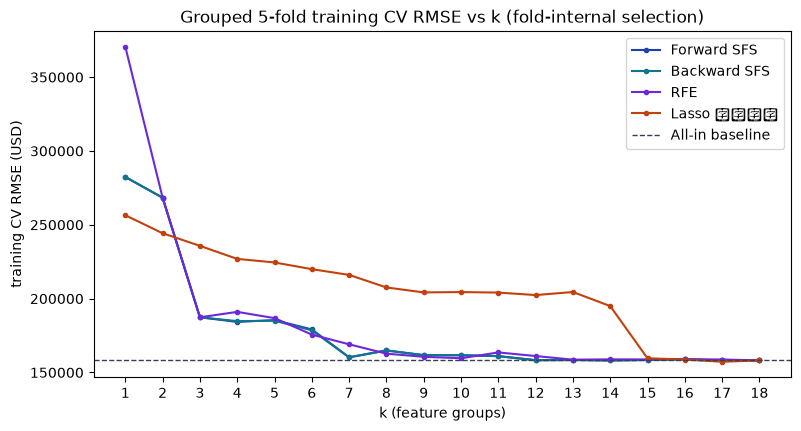

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = {"forward_sfs": "#1E40AF", "backward_sfs": "#0E7490", "rfe": "#6D28D9",
          "lasso_path": "#C2410C"}
for m, cands in path_candidates.items():
    ax.plot(range(1, 19), [c.cv_rmse for c in cands], marker="o", ms=3, color=colors[m],
            label=models.METHOD_LABELS[m])
ax.axhline(allin.cv_rmse, color="#334155", ls="--", lw=1, label="All-in baseline")
ax.set_xticks(range(1, 19))
ax.set_xlabel("k (feature groups)")
ax.set_ylabel("training CV RMSE (USD)")
ax.set_title("Grouped 5-fold training CV RMSE vs k (fold-internal selection)")
ax.legend()
plt.show()

### 4.3 對照模型：Ridge 與 Lasso（metric-only）

Ridge 與 Lasso 是**依老師補充建議**加入的對照模型，用全部 18 個 feature group：

- **標準化**：數值欄以當次訓練列的平均與母體標準差標準化，zipcode one-hot 欄維持 0／1；目標為 ln(price)，截距不懲罰。標準化只在當次訓練列上 fit（交叉驗證時是該 fold 的訓練列）。
- **alpha 只以 training CV 選**：在與所有方法相同的 5 個分組 fold 上，對網格中每個 alpha 以 fold 訓練列擬合、在驗證列上以 exp(log 預測) 計算 USD 尺度的指標；選 CV RMSE（USD）最小的 alpha（平手取較大的 alpha）。網格與整條 CV 曲線都記錄在 `model_data`。Test 列完全不參與（CC-1 第 1 點）。
- 選定 alpha 後在整個 training set 上重新擬合。兩者都是 **metric-only**：不提供預測區間、涵蓋率或即時預測，係數不匯出；不參與 CV winner 的競爭（CC-1 第 2、5 點）。它們的 Test 指標在全部選擇固定後、與 OLS 子集模型在同一次 Test 評估中各算一次（5.4），只出現在比較表。
- Adjusted R² 不適用於 Ridge／Lasso（見 5.2）。

In [19]:
cmp_selections, cmp_models, cmp_timing = comparison.run_metric_only(train)
alpha_table = pd.DataFrame([
    {"模型": comparison.LABELS[n], "alpha 網格": f"{min(s.grid):g} – {max(s.grid):g}（{len(s.grid)} 點）",
     "選定 alpha": s.alpha, "是否在網格邊界": s.at_grid_edge or "否",
     "CV RMSE (USD)": round(s.cv()["mean"]["rmse"], 1), "CV MAE (USD)": round(s.cv()["mean"]["mae"], 1),
     "CV R² (USD 尺度)": round(s.cv()["mean"]["r2"], 4), "時間（秒）": cmp_timing[n]["total"]}
    for n, s in cmp_selections.items()])
display(alpha_table)
print("All-in baseline（OLS）CV RMSE (USD):", round(allin.cv_rmse, 1))
for n, s in cmp_selections.items():
    if s.at_grid_edge == "lower":
        print(f"{comparison.LABELS[n]}: the CV RMSE is lowest at the smallest alpha of the grid; it keeps "
              "decreasing as the penalty weakens, so on these training folds regularization does not "
              "improve on the unpenalized fit (the model approaches the All-in OLS).")
    elif s.at_grid_edge == "upper":
        print(f"{comparison.LABELS[n]}: the CV RMSE is lowest at the largest alpha of the grid.")

,模型,alpha 網格,選定 alpha,是否在網格邊界,CV RMSE (USD),CV MAE (USD),CV R² (USD 尺度),時間（秒）
0,Ridge,0.0001 – 100000（37 點）,1.000000e-04,lower,158154.5,75657.7,0.801,1.8631
1,Lasso,1e-08 – 0.1（29 點）,1.000000e-08,lower,158154.9,75657.7,0.801,0.8799


All-in baseline（OLS）CV RMSE (USD): 158154.3
Ridge: the CV RMSE is lowest at the smallest alpha of the grid; it keeps decreasing as the penalty weakens, so on these training folds regularization does not improve on the unpenalized fit (the model approaches the All-in OLS).
Lasso: the CV RMSE is lowest at the smallest alpha of the grid; it keeps decreasing as the penalty weakens, so on these training folds regularization does not improve on the unpenalized fit (the model approaches the All-in OLS).


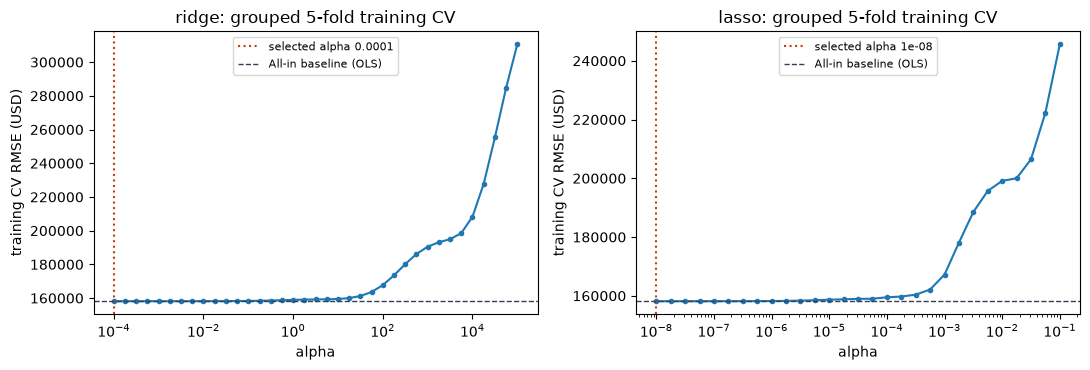

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (n, s) in zip(axes, cmp_selections.items()):
    ax.plot([r["alpha"] for r in s.cv_by_alpha], [r["rmse"] for r in s.cv_by_alpha], marker="o", ms=3)
    ax.axvline(s.alpha, color="#C2410C", ls=":", label=f"selected alpha {s.alpha:g}")
    ax.axhline(allin.cv_rmse, color="#334155", ls="--", lw=1, label="All-in baseline (OLS)")
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_ylabel("training CV RMSE (USD)")
    ax.set_title(f"{n}: grouped 5-fold training CV")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4.4 講義方法對照：p-value backward elimination

講義教的 p-value backward elimination 以 **group 層級的 partial F 檢定**執行：從全部 18 個 group 開始，每一步以目前的 group 擬合 OLS（ln(price)），對每個 group 檢定「移除它」的 F 統計量（F = ((RSS_移除後 − RSS_目前)/q) / (RSS_目前/df)，q 為該 group 增加的秩、df = n − rank），移除 p-value 最大且大於門檻 0.05 的 group，直到所有 group 的 p-value 都 ≤ 0.05。

- **選擇邊界與正式方法相同**（fold-internal selection）：每個 fold 只在該 fold 的訓練列上消去得到子集，再以該子集在驗證列上計算 USD 指標；CV 指標是 5 折平均。另在整個 training set 上執行一次，得到供顯示的 canonical subset。
- 它產生**單一子集、沒有 k 路徑**，只列為對照：不參與 CV winner，也**不在 Test 上評估**。

In [21]:
pvalue_entry = comparison.evaluate_pvalue_backward(train)
cmp_timing[comparison.PVALUE_KEY] = pvalue_entry["timing_s"]
print("canonical subset (whole training set), k =", pvalue_entry["k"], ":", pvalue_entry["canonical_groups"])
print("fold subsets: k =", [len(g) for g in pvalue_entry["fold_groups"]],
      "| folds equal to the canonical subset:", pvalue_entry["folds_agree"], "of", len(pvalue_entry["fold_groups"]))
print("status:", pvalue_entry["status"], "| time (s):", pvalue_entry["timing_s"])
print("training CV (USD):", {m: round(v, 4 if m == "r2" else 1) for m, v in pvalue_entry["cv"]["mean"].items()})
print("elimination on the whole training set:")
display(pd.DataFrame(pvalue_entry["elimination"]) if pvalue_entry["elimination"] else "no group removed")
pd.DataFrame(pvalue_entry["final_p_values"]).T.sort_values("p_value", ascending=False)

canonical subset (whole training set), k = 16 : ['date', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15']
fold subsets: k = [17, 17, 16, 16, 16] | folds equal to the canonical subset: 3 of 5
status: {'state': 'valid', 'reason': None} | time (s): {'cv': 0.8846, 'canonical': 0.2022, 'total': 1.0868}
training CV (USD): {'mae': 75676.0, 'mse': 26198607010.6, 'rmse': 158584.9, 'r2': 0.8}
elimination on the whole training set:


,removed,f,df_num,df_den,p_value,k_after
0,sqft_lot15,0.769400,1,17202,0.380415,17
1,bedrooms,3.318867,1,17203,0.068506,16


,f,df_num,df_den,p_value
yr_built,10.442153,1.0,17204.0,1.234033e-03
lat,40.423564,1.0,17204.0,2.096089e-10
long,53.862578,1.0,17204.0,2.246009e-13
floors,63.324450,1.0,17204.0,1.861467e-15
yr_renovated,70.871139,2.0,17204.0,2.224107e-31
bathrooms,158.407734,1.0,17204.0,3.638559e-36
sqft_above,246.410982,1.0,17204.0,3.797982e-55
sqft_lot,313.136292,1.0,17204.0,1.867818e-69
date,318.583183,1.0,17204.0,1.277107e-70
sqft_living15,535.723742,1.0,17204.0,9.702455e-117


## 5. Evaluation

### 5.1 CV winner

各方法的 **CV winner** 是有效候選中 CV RMSE（USD）最小的 k（平手取較小的 k）；**整體 CV winner** 是四個方法的 CV winner 與 All-in baseline 中 CV RMSE 最小者（平手依固定的方法順序 All-in、Forward SFS、Backward SFS、RFE、Lasso 路徑排序）。只有有效候選（全部 fold 有效、canonical fit 有效）可以成為 winner；Ridge／Lasso 對照模型不參與。

Test 評估的授權集合＝各方法 CV winner ∪ {All-in} ∪ {整體 CV winner}，同一模型只評估一次：模型是 canonical subset 在整個 training set 上擬合的 OLS，所以 canonical subset 相同的兩個 winner 是同一個模型（例如某方法在 k = 18 的子集就是 All-in baseline），只以一個鍵（`test_model_key`）評估。

**選擇偏誤**：在 18 個 k 與多個方法之中取 CV RMSE 最小者，會使 CV winner 的 CV 分數帶有樂觀偏誤，不是它表現的不偏估計；全部選擇凍結之後的 Test 評估才是 CV winner 表現的獨立估計。此外，CV 指標估計的是「方法在 k 下的程序」，Test 評估的則是 canonical subset 在整個 training set 上擬合的模型。Test 排名與 CV 排名不同時不換模型。

In [22]:
winners = models.determine_winners(allin, path_candidates)
winner_table = pd.DataFrame([
    {"方法": models.METHOD_LABELS[m], "CV winner": w["model_key"], "k": w["k"],
     "CV RMSE (USD)": round(w["cv_rmse"], 1), "Test 評估的鍵": w["test_model_key"]}
    for m, w in winners["method_winners"].items()])
display(winner_table)
print("All-in CV RMSE (USD):", round(winners["allin"]["cv_rmse"], 1))
print("overall CV winner:", winners["overall"])
print("authorized test models:", winners["authorized_test_models"])

,方法,CV winner,k,CV RMSE (USD),Test 評估的鍵
0,Forward SFS,forward_sfs_k17,17,158098.3,forward_sfs_k17
1,Backward SFS,backward_sfs_k17,17,158098.3,forward_sfs_k17
2,RFE,rfe_k18,18,158154.3,allin
3,Lasso 路徑排序,lasso_path_k17,17,157253.9,forward_sfs_k17


All-in CV RMSE (USD): 158154.3
overall CV winner: {'model_key': 'lasso_path_k17', 'method': 'lasso_path', 'cv_rmse': 157253.88439268037, 'test_model_key': 'forward_sfs_k17'}
authorized test models: ['allin', 'forward_sfs_k17']


### 5.2 Adjusted R²

Adjusted R² **只對 OLS 子集模型（含 All-in）**計算：在 log(price) 尺度、以整個 training set 的擬合、n_train 與實際 model rank（含截距）套古典公式 1 − (1 − R²)(n − 1)/(n − rank)，與 log 尺度 R² 並列。它不用於選模（選模只用 CV RMSE）。Ridge／Lasso（有懲罰、沒有古典自由度）與 CV 聚合值（USD 尺度、驗證列上的平均）都**不適用**，下表標「不適用」。

In [23]:
NA = "不適用"
adj_rows = []
def _adj_row(label, fit, cv):
    return {"模型": label, "n_train": fit["n_train"], "rank（含截距）": fit["rank"],
            "R²（log，全訓練集擬合）": round(fit["r2_log"], 4), "Adjusted R²（log，全訓練集擬合）": round(fit["adj_r2_log"], 4),
            "CV R²（USD 尺度，5 折平均）": round(cv["mean"]["r2"], 4), "Adjusted R²（CV 聚合值）": NA}
adj_rows.append(_adj_row("All-in baseline k=18", allin_entry["fit"], allin_entry["cv"]))
by_key = {c.key: c for cands in path_candidates.values() for c in cands}
for m, w in winners["method_winners"].items():
    e = by_key[w["model_key"]].to_entry()
    adj_rows.append(_adj_row(f"{models.METHOD_LABELS[m]} k={w['k']}（CV winner）", e["fit"], e["cv"]))
adj_rows.append(_adj_row(f"p-value backward k={pvalue_entry['k']}（講義對照）", pvalue_entry["fit_summary"], pvalue_entry["cv"]))
for n, s in cmp_selections.items():
    adj_rows.append({"模型": f"{comparison.LABELS[n]}（alpha {s.alpha:g}）", "n_train": prepared.n_train,
                     "rank（含截距）": NA, "R²（log，全訓練集擬合）": NA, "Adjusted R²（log，全訓練集擬合）": NA,
                     "CV R²（USD 尺度，5 折平均）": round(s.cv()["mean"]["r2"], 4), "Adjusted R²（CV 聚合值）": NA})
pd.DataFrame(adj_rows)

,模型,n_train,rank（含截距）,R²（log，全訓練集擬合）,Adjusted R²（log，全訓練集擬合）,CV R²（USD 尺度，5 折平均）,Adjusted R²（CV 聚合值）
0,All-in baseline k=18,17290,88,0.8791,0.8785,0.8010,不適用
1,Forward SFS k=17（CV winner）,17290,87,0.8791,0.8785,0.8015,不適用
2,Backward SFS k=17（CV winner）,17290,87,0.8791,0.8785,0.8015,不適用
3,RFE k=18（CV winner）,17290,88,0.8791,0.8785,0.8010,不適用
4,Lasso 路徑排序 k=17（CV winner）,17290,87,0.8791,0.8785,0.8034,不適用
5,p-value backward k=16（講義對照）,17290,86,0.879,0.8785,0.8000,不適用
6,Ridge（alpha 0.0001）,17290,不適用,不適用,不適用,0.8010,不適用
7,Lasso（alpha 1e-08）,17290,不適用,不適用,不適用,0.8010,不適用


### 5.3 預測區間：定義、假設與限制

對 OLS 子集模型，在 log(price) 尺度計算參數式 95% 預測區間，再以 exp 轉回 USD（因此區間不對稱）：

ŷ_log ± t(0.975, df_resid) · √( s² · (1 + x₀ᵀ (XᵀX)⁻¹ x₀) )

- **點預測**：exp(ŷ_log)，不作偏誤修正。它估計的是給定特徵下價格的**條件中位數**（在 log 尺度殘差對稱的假設下），**不是條件平均**；條件平均會比它高。
- **假設**：殘差常態、同質變異、彼此獨立。房價資料可能不滿足這些假設；特徵選擇之後再做推論（區間沒有把選擇的不確定性算進去），以及可能的模型誤設，都會影響名目涵蓋率。因此本專案**不宣稱保證 95% 的經驗涵蓋率**；Test set 上的經驗涵蓋率是對它的檢驗，偏離 95% 時分析原因並連到假設診斷，不自動判定失敗。
- **涵蓋率的抽樣不確定性**：以 1.96·√(p(1−p)/n_test) 表示。這是**假設各筆涵蓋事件獨立的二項近似**；Test set 含同一房屋的重複交易，涵蓋事件不保證獨立，所以這個近似的準確度未經估計，這裡不陳述偏差的方向或幅度。報告會同時列出 Test 的房屋數與重複交易筆數。
- 涵蓋以閉區間判定（lower ≤ 實際價格 ≤ upper）；平均寬度以 USD 計。

下面以 All-in baseline 的全訓練集擬合，對 training 列的第一筆示範區間的計算（只用 training 列）。

In [24]:
example_row = train.head(1)
point, lower, upper, n_unseen = allin.model.predict_usd(example_row)
print(f"actual {example_row['price'].iloc[0]:,.0f} USD | point {point[0]:,.0f} | 95% PI {lower[0]:,.0f} - {upper[0]:,.0f}")

actual 221,900 USD | point 239,353 | 95% PI 167,049 - 342,953


### 5.4 唯一一次的 Test 評估（G-3）與匯出

到這裡，全部的模型選擇都已只用 training set 固定：四個方法各 k 的子集與 CV、各方法的 CV winner、All-in、整體 CV winner（5.1），以及 Ridge／Lasso 的 alpha（4.3）。Test 列的特徵與價格只能經由 `hw2.testgate.TestGate` 載入：

1. `open` 凍結這份選擇（完整的 `winners` 與兩個 metric-only 模型的 alpha；缺任何一項都拒絕開啟），並記錄凍結內容的 sha256 摘要。
2. `evaluate` 在同一次執行中只執行一次：載入 Test 列，對授權集合中的每個 OLS 子集模型（各方法 CV winner ∪ {All-in} ∪ {整體 CV winner}，同一模型只評估一次）計算逐筆點預測與 95% PI，並對 Ridge、Lasso 各計算一次 USD 尺度的 MAE、MSE、RMSE、R²（metric-only）。第二次呼叫會報錯。
3. 同一個匯出程式立即寫出 `model_data` 的 `test_inputs`（全部 Test 列的原始值與實際價格、房屋數、重複交易筆數、被編為基準的未見 zipcode 筆數）與 `test`，以及結果表 CSV。

Test 結果不回饋任何選擇：之後沒有任何程式讀取它們來改變 winner、alpha 或子集；Test 排名與 CV 排名不同時不換模型。Dashboard 只讀取匯出的結果，任何操作都不會觸發新的 Test 評估。

In [25]:
alphas = {name: sel.alpha for name, sel in cmp_selections.items()}
print("frozen selection:")
print("  authorized OLS subset models:", winners["authorized_test_models"])
print("  overall CV winner:", winners["overall"]["model_key"], "| metric-only alphas:", alphas)
print("  selection digest:", testgate.selection_digest(winners, alphas))
pool = [allin] + [c for cands in path_candidates.values() for c in cands]
gate = testgate.TestGate(prepared)
print("gate before opening:", gate.status())
gate.open(winners, alphas)
evaluation = gate.evaluate(testgate.ols_models_for(winners, pool), cmp_models)

timings = dict(prepared.timings_s)
timings.update({"allin_cv": allin.timing_s["cv"], "allin_canonical_fit": allin.timing_s["canonical_fit"]})
timings.update({f"path_{m}": t["total"] for m, t in path_timing.items()})
timings.update({f"{m}_total": t["total"] for m, t in cmp_timing.items()})
timings.update({f"test_{k}": v for k, v in evaluation.timing_s.items()})
model_data = export.build_model_data(prepared, timings_s=timings, fixture=False, allin=allin,
                                     winners=winners, methods=path_candidates,
                                     evaluation=evaluation, path_timing=path_timing,
                                     metric_only=cmp_selections, pvalue=pvalue_entry,
                                     comparison_timing=cmp_timing,
                                     code_revision=export.code_revision())
json_path, js_path = export.write_model_data(model_data)
table_paths = export.write_result_tables(model_data)
for p in (json_path, js_path, *table_paths):
    print(rel(p), p.stat().st_size, "bytes")
print("sections:", model_data["meta"]["sections_written"])
print("gate after the evaluation:", gate.status())
print("manifest:", evaluation.manifest)
print("result digest (test_inputs + test):", export.result_digest(model_data))

frozen selection:
  authorized OLS subset models: ['allin', 'forward_sfs_k17']
  overall CV winner: lasso_path_k17 | metric-only alphas: {'ridge': 0.0001, 'lasso': 1e-08}
  selection digest: 44f7723e4023afc3e8e997f42bf4eb59db392af81cced11743757a9857cb4b28
gate before opening: {'state': 'closed', 'official_data': True, 'official_gate_enabled': True}


results/model_data.json 9787774 bytes
assets/model_data.js 9787860 bytes
results/tables/cv_by_method_k.csv 18882 bytes
results/tables/comparison.csv 4999 bytes
results/tables/alpha_cv.csv 6845 bytes
sections: ['meta', 'preprocess', 'inputs', 'methods', 'baselines.allin', 'baselines.ridge', 'baselines.lasso', 'baselines.pvalue_backward', 'winners', 'test_inputs', 'test']
gate after the evaluation: {'state': 'evaluated', 'official_data': True, 'official_gate_enabled': True}
manifest: {'run_id': 'fe76019b9af84b1e8ff46095d5ac0fb2', 'official_data': True, 'data_sha256': 'd0875baa0251b21d4bdc9d2ae940a4fe0bb6009824f23dd0e2a5b2bf04557b7e', 'opened_at': '2026-10-18T13:37:32+00:00', 'evaluated_at': '2026-10-18T13:37:32+00:00', 'selection_digest': '44f7723e4023afc3e8e997f42bf4eb59db392af81cced11743757a9857cb4b28', 'selection_digest_rule': 'sha256 of the sorted-key JSON of the frozen winners and metric-only alphas (hw2.testgate.selection_digest)', 'authorized_test_models': ['allin', 'forward_sfs_k

In [26]:
# The evaluation runs once per run: a second call is refused before anything is loaded or scored.
try:
    gate.evaluate(testgate.ols_models_for(winners, pool), cmp_models)
except testgate.TestGateError as err:
    print("second evaluation refused:", err)

second evaluation refused: the test evaluation already ran in this run; it runs once


### 5.5 Test 評估結果

下表把**訓練 CV（USD）**與 **Test 評估（USD）**分欄呈現，不混用：每個 CV winner 各佔一列、以自己的身分標示；canonical subset 相同的 winner 是同一個模型，Test 只評估一次，數值經 `test_model_key` 取得並註明共用。Ridge／Lasso 的 Test 指標只是描述性對照（metric-only，沒有預測區間與涵蓋率）；p-value backward 不在 Test 上評估。CV winner 的 CV 分數帶有選擇造成的樂觀偏誤，Test 評估才是獨立估計；Test 排名與 CV 排名不同時不換模型。

In [27]:
comparison_table = pd.DataFrame(export.comparison_rows(model_data)).set_index("row")
cv_cols = {"cv_rmse_usd": "RMSE", "cv_rmse_std_usd": "RMSE 標準差", "cv_mae_usd": "MAE", "cv_r2_usd_scale": "R²"}
test_cols = {"test_rmse_usd": "RMSE", "test_mae_usd": "MAE", "test_r2_usd_scale": "R²",
             "test_coverage": "PI 經驗涵蓋率", "test_mean_pi_width_usd": "PI 平均寬度"}
shown = pd.concat({"訓練 CV（USD）": comparison_table[list(cv_cols)].rename(columns=cv_cols),
                   "Adjusted R²（log，全訓練集擬合）": comparison_table[["adj_r2_log_full_training_fit"]].rename(
                       columns={"adj_r2_log_full_training_fit": ""}),
                   "Test 評估（USD）": comparison_table[list(test_cols)].rename(columns=test_cols)}, axis=1)
def _fmt(v):
    if isinstance(v, float):
        return f"{v:.4f}" if abs(v) <= 1 else f"{v:,.0f}"
    return v

display(shown.apply(lambda col: col.map(_fmt)))
display(comparison_table[["role", "test_model_key", "notes"]])
n_ols = len(model_data["winners"]["authorized_test_models"])
n_metric = sum(1 for v in model_data["test"].values() if v["kind"] == "metric_only")
print(f"models scored on the test set: {n_ols} distinct OLS subset models (the authorized set) "
      f"+ {n_metric} metric-only models (Ridge, Lasso); each once")

訓練 CV（USD）                          Adjusted R²（log，全訓練集擬合）                        Test 評估（USD）  \
                                    RMSE RMSE 標準差     MAE      R²                                                        RMSE   
row                                                                                                                             
All-in baseline k=18             158,154   35,930  75,658  0.8010                  0.8785                             183,597   
Forward SFS k=17                 158,098   35,568  75,655  0.8015                  0.8785                             183,370   
Backward SFS k=17                158,098   35,568  75,655  0.8015                  0.8785                             183,370   
RFE k=18                         158,154   35,930  75,658  0.8010                  0.8785                             183,597   
Lasso 路徑排序 k=17                  157,254   35,631  75,670  0.8034                  0.8785                             183,370   
Ridge (alpha 0.0001)             158,154   35,930  75,658  0.8010          not applicable                             183,597   
Lasso (alpha 1e-08)              158,155   35,930  75,658  0.8010          not applicable                             183,597   
p-value backward（講義對照） (k=16)    158,585   36,219  75,676  0.8000                  0.8785  not evaluated (lecture comparison)   

                                                                                                                                           \
                                                              MAE                                  R²                            PI 經驗涵蓋率   
row                                                                                                                                         
All-in baseline k=18                                       78,114                              0.7828                              0.9443   
Forward SFS k=17                                           78,100                              0.7834                              0.9445   
Backward SFS k=17                                          78,100                              0.7834                              0.9445   
RFE k=18                                                   78,114                              0.7828                              0.9443   
Lasso 路徑排序 k=17                                            78,100                              0.7834                              0.9445   
Ridge (alpha 0.0001)                                       78,114                              0.7828        not applicable (metric-only)   
Lasso (alpha 1e-08)                                        78,114                              0.7828        not applicable (metric-only)   
p-value backward（講義對照） (k=16)  not evaluated (lecture comparison)  not evaluated (lecture comparison)  not evaluated (lecture comparison)   

                                                                   
                                                          PI 平均寬度  
row                                                                
All-in baseline k=18                                      401,087  
Forward SFS k=17                                          401,052  
Backward SFS k=17                                         401,052  
RFE k=18                                                  401,087  
Lasso 路徑排序 k=17                                           401,052  
Ridge (alpha 0.0001)                 not applicable (metric-only)  
Lasso (alpha 1e-08)                  not applicable (metric-only)  
p-value backward（講義對照） (k=16)  not evaluated (lecture comparison)

,role,test_model_key,notes
row,,,
All-in baseline k=18,All-in baseline,allin,same model as RFE k=18; scored once on the tes...
Forward SFS k=17,method CV winner,forward_sfs_k17,"same model as Backward SFS k=17, Lasso 路徑排序 k=..."
Backward SFS k=17,method CV winner,forward_sfs_k17,"same model as Forward SFS k=17, Lasso 路徑排序 k=1..."
RFE k=18,method CV winner,allin,same model as All-in baseline k=18; scored onc...
Lasso 路徑排序 k=17,method CV winner,forward_sfs_k17,overall CV winner; same model as Forward SFS k...
Ridge (alpha 0.0001),metric-only comparison,ridge,alpha chosen by training CV; not a CV winner c...
Lasso (alpha 1e-08),metric-only comparison,lasso,alpha chosen by training CV; not a CV winner c...
p-value backward（講義對照） (k=16),lecture comparison,,"group partial F tests, threshold 0.05; never a..."


models scored on the test set: 2 distinct OLS subset models (the authorized set) + 2 metric-only models (Ridge, Lasso); each once


In [28]:
ti = model_data["test_inputs"]
print("n_test:", ti["n_rows"], "| test houses:", ti["n_houses"], "| repeat sales in the test set:", ti["n_repeat_sales"],
      "| test rows with a zipcode unseen in training (encoded as the baseline):", ti["n_unseen_zipcode"])
for key in model_data["winners"]["authorized_test_models"]:
    t = model_data["test"][key]
    half = t["coverage_uncertainty"]["half_width_95"]
    gap = 100 * (t["coverage"] - 0.95)
    print(f"{key}: coverage {100 * t['coverage']:.2f}% ({t['n_covered']}/{t['n_test']}), "
          f"{gap:+.2f} percentage points from the nominal 95%; binomial approximation +/- {100 * half:.2f} "
          f"points (assumes independent coverage events); mean PI width {t['mean_width']:,.0f} USD")

n_test: 4323 | test houses: 4287 | repeat sales in the test set: 36 | test rows with a zipcode unseen in training (encoded as the baseline): 0
allin: coverage 94.43% (4082/4323), -0.57 percentage points from the nominal 95%; binomial approximation +/- 0.68 points (assumes independent coverage events); mean PI width 401,087 USD
forward_sfs_k17: coverage 94.45% (4083/4323), -0.55 percentage points from the nominal 95%; binomial approximation +/- 0.68 points (assumes independent coverage events); mean PI width 401,052 USD


## 6. Deployment

（本章尚未完成：最終模型、`predict_price()` 示範、模型解釋與使用限制會在後續步驟加入。）